# NumCompute Stream: streaming decision-tree demo

This notebook runs the full workflow the brief asks for:

1. load a CSV with the package's own I/O module (`numcompute_stream.io`);
2. split it into chunks to simulate data arriving over time;
3. train a preprocessing + decision-tree pipeline incrementally with `.partial_fit()`;
4. log metrics per chunk with `StreamTrainer` and plot them with `visualise.py`.

**Data.** `data/loan_stream.csv` holds 12,000 loan applications in time order
(regenerate it with `python demo/make_dataset.py`). It has missing values, a new
region category (`online`) that only appears after row 4,000, and a **change in the
underlying rule at row 7,000** (concept drift), so we can watch the buffered tree
recover after the drift.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "demo" else ROOT
sys.path.insert(0, str(ROOT))                       # use the package from this repo

import numpy as np
import matplotlib.pyplot as plt
import numcompute_stream as ncs
from numcompute_stream import (io, visualise, Pipeline, ColumnTransformer, SimpleImputer,
                               StandardScaler, OneHotEncoder, DecisionTreeClassifier,
                               StreamTrainer, StreamingStats, StreamingHistogram)

%matplotlib inline
DATA = ROOT / "demo" / "data" / "loan_stream.csv"
OUT = ROOT / "demo" / "output"; OUT.mkdir(exist_ok=True)
print("numcompute_stream", ncs.__version__, "| numpy", np.__version__)

numcompute_stream 2.2.0 | numpy 2.4.6


## 1. Load the CSV with the custom I/O pipeline

In [2]:
frame = io.read_csv(DATA)
print(frame)
NUM = frame.numeric_columns(); NUM.remove("default")
CAT = frame.categorical_columns()
TARGET = "default"
print("numeric:", NUM)
print("categorical:", CAT)

missing = {c: int(np.isnan(frame[c]).sum()) for c in NUM}
missing.update({c: int((frame[c] == "").sum()) for c in CAT})
print("missing cells per column:", {k: v for k, v in missing.items() if v})

Frame(n_rows=12000, columns=['age', 'income', 'loan_amount', 'credit_score', 'debt_to_income', 'years_employed', 'late_payments', 'region', 'loan_purpose', 'default'])
numeric: ['age', 'income', 'loan_amount', 'credit_score', 'debt_to_income', 'years_employed', 'late_payments']
categorical: ['region', 'loan_purpose']
missing cells per column: {'income': 502, 'credit_score': 480, 'debt_to_income': 475, 'years_employed': 485, 'region': 206}


## 2. Split into chunks and look at the stream

`io.iter_csv` reads the file lazily, 250 rows at a time, so the data never has to be
in memory all at once. While streaming we update running statistics with
`StreamingStats.update_stats()` and watch the default rate per chunk.

In [3]:
CHUNK = 250
stats = StreamingStats()
hist = StreamingHistogram(bins=20, range=(0, 1), window=8)   # debt-to-income, last 8 chunks
default_rate = []
for chunk in io.iter_csv(DATA, CHUNK):
    stats.update_stats(chunk.to_array(NUM))
    hist.update_stats(chunk["debt_to_income"])
    default_rate.append(chunk[TARGET].mean())

print(f"{len(default_rate)} chunks of {CHUNK} rows")
for name, m, s, n in zip(NUM, stats.mean, stats.std(), stats.count_):
    print(f"  {name:<15} mean={m:9.3f}  std={s:8.3f}  observed={n}")
check = frame.to_array(NUM)
print("matches one-pass NumPy:", np.allclose(stats.mean, np.nanmean(check, axis=0)))

48 chunks of 250 rows
  age             mean=   44.138  std=  15.320  observed=12000
  income          mean=   71.837  std=  33.860  observed=11498
  loan_amount     mean=   30.041  std=  20.262  observed=12000
  credit_score    mean=  669.976  std=  69.153  observed=11520
  debt_to_income  mean=    0.331  std=   0.174  observed=11525
  years_employed  mean=    5.980  std=   5.894  observed=11515
  late_payments   mean=    0.689  std=   0.833  observed=12000
matches one-pass NumPy: True


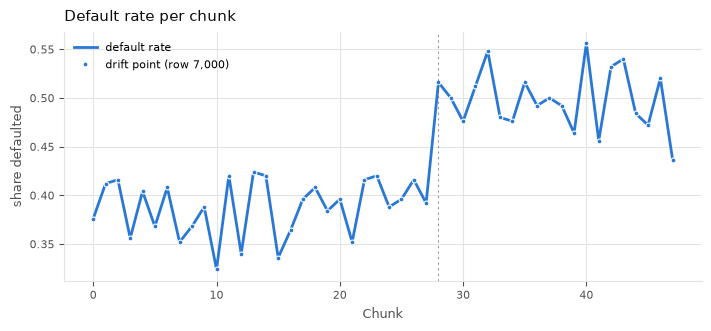

In [4]:
fig, ax = visualise.plot_metric_over_time(default_rate, "Default rate per chunk", "share defaulted",
                                         retrain_points=[7000 // CHUNK])
ax.legend(["default rate", "drift point (row 7,000)"], frameon=False, fontsize=8)
plt.show()

## 3. Build the pipeline and train it with `.partial_fit()`

Numeric columns are imputed (running median) and scaled (running mean/variance);
categorical columns are one-hot encoded with categories added as they appear. The
encoder goes last so new columns are appended at the end. The tree retrains every
`buffer_size` samples.

In [5]:
def make_pipeline(buffer_size=1000, max_depth=5):
    numeric = Pipeline([("impute", SimpleImputer("median", random_state=0)),
                        ("scale", StandardScaler())])
    prep = ColumnTransformer([("num", numeric, NUM), ("cat", OneHotEncoder(), CAT)])
    return Pipeline([("prep", prep),
                     ("model", DecisionTreeClassifier(max_depth=max_depth, buffer_size=buffer_size))])

pipe = make_pipeline(buffer_size=1000)
pipe

Pipeline([('prep', <numcompute_stream.pipeline.ColumnTransformer object at 0x160c93380>), ('model', DecisionTreeClassifier(max_depth=5, criterion='gini', buffer_size=1000))])

In [6]:
# the plain loop the brief describes: one partial_fit per chunk
for i, chunk in enumerate(io.iter_csv(DATA, CHUNK)):
    pipe.partial_fit(chunk, chunk[TARGET].astype(int))
    tree = pipe["model"]
    if i < 10 or tree.buffer_fill == 0 and i % 8 == 3:
        print(f"chunk {i:>2}: retrains={tree.n_retrains_}  buffer={tree.buffer_fill:>4}  "
              f"one-hot columns={pipe['prep'].transformers[1][1].n_features_out_}")
print("final one-hot categories:", pipe["prep"].transformers[1][1].categories_)

chunk  0: retrains=0  buffer= 250  one-hot columns=8
chunk  1: retrains=0  buffer= 500  one-hot columns=8
chunk  2: retrains=0  buffer= 750  one-hot columns=8
chunk  3: retrains=1  buffer=   0  one-hot columns=8
chunk  4: retrains=1  buffer= 250  one-hot columns=8
chunk  5: retrains=1  buffer= 500  one-hot columns=8
chunk  6: retrains=1  buffer= 750  one-hot columns=8
chunk  7: retrains=2  buffer=   0  one-hot columns=8
chunk  8: retrains=2  buffer= 250  one-hot columns=8
chunk  9: retrains=2  buffer= 500  one-hot columns=8
chunk 11: retrains=3  buffer=   0  one-hot columns=8
chunk 19: retrains=5  buffer=   0  one-hot columns=9
chunk 27: retrains=7  buffer=   0  one-hot columns=9
chunk 35: retrains=9  buffer=   0  one-hot columns=9
chunk 43: retrains=11  buffer=   0  one-hot columns=9
final one-hot categories: [['south', 'north', 'east', 'west', 'online'], ['business', 'education', 'car', 'home']]


## 4. Prequential run with logging (`StreamTrainer`)

Each chunk is **scored first, then used for training**, so every prediction is made
on data the model has not seen. The log records chunk, cumulative and rolling
accuracy, AUC, fit time, retrains, buffer fill and model memory.

In [7]:
trainer = StreamTrainer(make_pipeline(buffer_size=1000), rolling_window=1000,
                        name="tree b=1000", verbose=True)
for chunk in io.iter_csv(DATA, CHUNK):
    trainer.step(chunk, chunk[TARGET].astype(int))
trainer.to_csv(OUT / "stream_log_b1000.csv")
trainer.summary()

[tree b=1000] chunk   0 | n= 250 | acc=   nan | cum_acc=   nan | buffer  fill=  250 | fit=   1.06 ms | mem=    31.2 KiB
[tree b=1000] chunk   1 | n= 250 | acc=   nan | cum_acc=   nan | buffer  fill=  500 | fit=   0.68 ms | mem=    62.5 KiB
[tree b=1000] chunk   2 | n= 250 | acc=   nan | cum_acc=   nan | buffer  fill=  750 | fit=   0.56 ms | mem=    93.8 KiB
[tree b=1000] chunk   3 | n= 250 | acc=   nan | cum_acc=   nan | RETRAIN fill=    0 | fit=  13.76 ms | mem=     3.5 KiB
[tree b=1000] chunk   4 | n= 250 | acc= 0.788 | cum_acc= 0.788 | buffer  fill=  250 | fit=   0.66 ms | mem=    34.7 KiB
[tree b=1000] chunk   5 | n= 250 | acc= 0.708 | cum_acc= 0.748 | buffer  fill=  500 | fit=   0.64 ms | mem=    66.0 KiB
[tree b=1000] chunk   6 | n= 250 | acc= 0.820 | cum_acc= 0.772 | buffer  fill=  750 | fit=   0.66 ms | mem=    97.2 KiB
[tree b=1000] chunk   7 | n= 250 | acc= 0.796 | cum_acc= 0.778 | RETRAIN fill=    0 | fit=  14.36 ms | mem=     4.5 KiB
[tree b=1000] chunk   8 | n= 250 | acc= 

{'final_accuracy': 0.7742727272727272,
 'final_f1_macro': 0.7684865734291328,
 'chunks': 48,
 'samples': 12000,
 'retrains': 12,
 'total_fit_time_s': 0.21124266399419867,
 'peak_memory_bytes': 106307.0,
 'final_rolling_accuracy': 0.806}

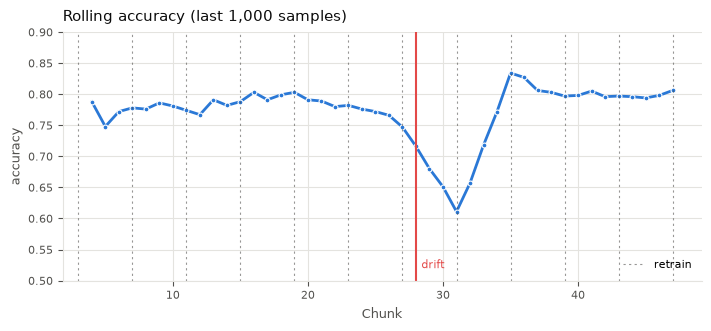

In [8]:
h = trainer.history
fig, ax = visualise.plot_metric_over_time(h["rolling_accuracy"], "Rolling accuracy (last 1,000 samples)",
                                         "accuracy", retrain_points=trainer.retrain_chunks(),
                                         ylim=(0.5, 0.9), save_path=OUT / "rolling_accuracy.png")
ax.axvline(7000 // CHUNK, color="#e34948", lw=1.5); ax.text(7000 // CHUNK + 0.4, 0.52, "drift", color="#e34948", fontsize=8)
plt.show()

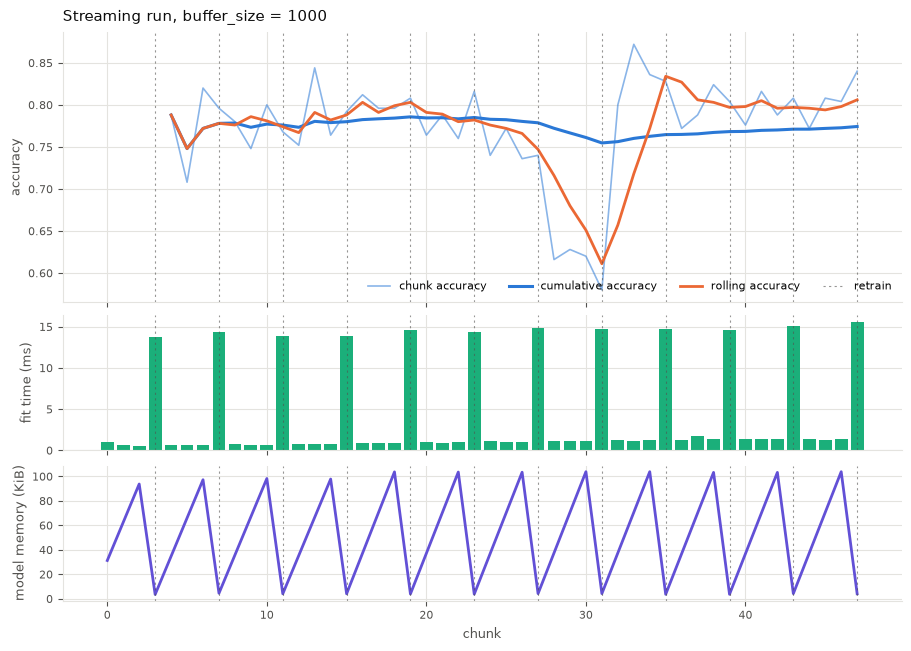

In [9]:
fig, axes = visualise.plot_stream_dashboard(h, title="Streaming run, buffer_size = 1000",
                                           save_path=OUT / "dashboard.png")
plt.show()

## 5. Comparing buffer sizes

A small buffer retrains often on little data (fast to adapt, noisier); a large buffer
trains on more data but reacts slowly to drift.

buffer   250: cumulative acc=0.743  retrains=48  total fit time=0.26s
buffer  1000: cumulative acc=0.774  retrains=12  total fit time=0.21s
buffer  4000: cumulative acc=0.717  retrains= 3  total fit time=0.20s


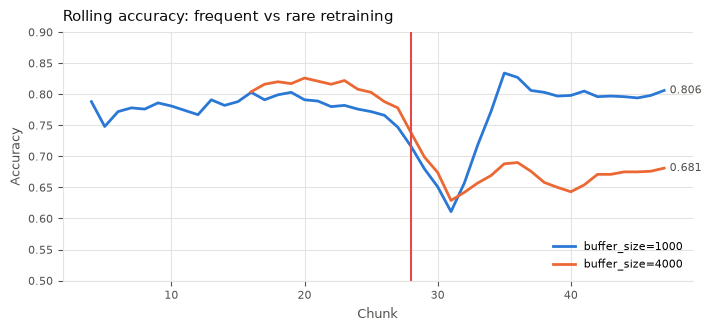

In [10]:
runs = {}
for b in (250, 1000, 4000):
    t = StreamTrainer(make_pipeline(buffer_size=b), rolling_window=1000, name=f"b={b}")
    for chunk in io.iter_csv(DATA, CHUNK):
        t.step(chunk, chunk[TARGET].astype(int))
    runs[b] = t
    s = t.summary()
    print(f"buffer {b:>5}: cumulative acc={s['final_accuracy']:.3f}  retrains={s['retrains']:>2}  "
          f"total fit time={s['total_fit_time_s']:.2f}s")

fig, ax = visualise.compare_models(runs[1000].history["rolling_accuracy"],
                                   runs[4000].history["rolling_accuracy"],
                                   labels=("buffer_size=1000", "buffer_size=4000"),
                                   title="Rolling accuracy: frequent vs rare retraining",
                                   ylim=(0.5, 0.9), save_path=OUT / "compare_buffers.png")
ax.axvline(7000 // CHUNK, color="#e34948", lw=1.5)
plt.show()

## 6. Predictions vs ground truth on the latest chunk

The trainer keeps the predictions it made for the last chunk *before* training on it,
so this is an honest out-of-sample view (predicting again now would score the tree on
rows it has just been trained on).

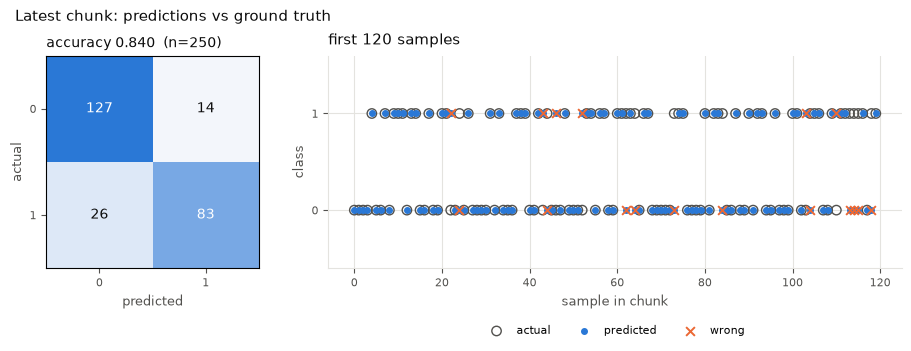

(array([[127,  14],
       [ 26,  83]]), array([0, 1]))


In [11]:
y_true, y_pred = trainer.last_y_true_, trainer.last_y_pred_
fig, axes = visualise.plot_predictions_vs_ground_truth(y_true, y_pred, labels=[0, 1],
                                                      save_path=OUT / "predictions.png")
plt.show()
print(ncs.metrics.confusion_matrix(y_true, y_pred))

## 7. What the current tree learned

depth=5  leaves=29  trained on the last 1000 samples
|--- debt_to_income <= 0.332
|   |--- late_payments <= 0.374
|   |   |--- region=online <= 0.5
|   |   |   |--- late_payments <= -0.228
|   |   |   |   |--- age <= -1.676
|   |   |   |   |   |--- class: 0  (n=6)
|   |   |   |   |--- age >  -1.676
|   |   |   |   |   |--- class: 0  (n=256)
|   |   |   |--- late_payments >  -0.228
|   |   |   |   |--- age <= -0.99
|   |   |   |   |   |--- class: 1  (n=32)
|   |   |   |   |--- age >  -0.99
|   |   |   |   |   |--- class: 0  (n=108)
|   |   |--- region=online >  0.5
|   |   |   |--- debt_to_income <= -0.53
|   |   |   |   |--- late_payments <= -0.228
|   |   |   |   |   |--- class: 0  (n=39)
|   |   |   |   |--- late_payments >  -0.228
|   |   |   |   |   |--- class: 1  (n=18)
|   |   |   |--- debt_to_income >  -0.53
|   |   |   |   |--- credit_score <= 2.0
|   |   |   |   |   |--- class: 1  (n=48)
|   |   |   |   |--- credit_score >  2.0
|   |   |   |   |   |--- class: 0  (n=4)
|   |---

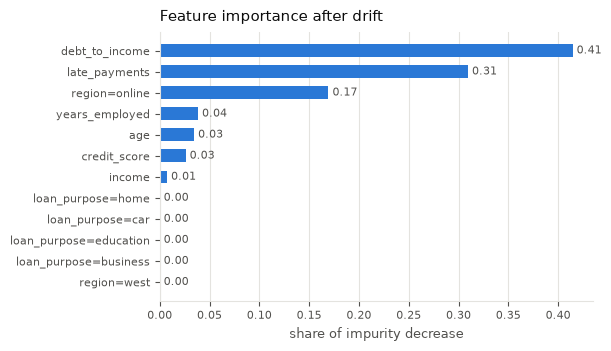

In [12]:
names = trainer.model["prep"].get_feature_names_out()
tree = trainer.model["model"]
print(f"depth={tree.get_depth()}  leaves={tree.get_n_leaves()}  trained on the last {tree.n_node_samples_[0]} samples")
print(tree.export_text(names)[:1800])
fig, ax = visualise.plot_feature_importances(names, tree.feature_importances_,
                                             title="Feature importance after drift",
                                             save_path=OUT / "importances.png")
plt.show()

After the drift the tree leans on `debt_to_income`, `late_payments` and
`region=online`, which is the new rule in the data; the credit score that drove the
earlier rule has dropped down the list. The buffered retrain is what let the model
pick this up.